In [2]:
# --------------------------------------------
# Step 1: Download Data (Edited)
# --------------------------------------------

tickers = ["RELIANCE.NS", "TCS.NS", "INFY.NS", "HDFCBANK.NS", "ICICIBANK.NS"]

prices = pd.DataFrame()

for ticker in tickers:
    try:
        data = yf.download(
            ticker,
            start="2020-01-01",
            end="2025-01-01",
            auto_adjust=True,
            progress=False
        )["Close"]

        prices[ticker] = data

    except Exception as e:
        print(f"Failed to download {ticker}: {e}")

# Remove rows with missing values
prices = prices.dropna()

# Compute daily returns
returns = prices.pct_change(fill_method=None).dropna()

# Check downloaded data
print("Price Shape:", prices.shape)
print("Return Shape:", returns.shape)

if prices.empty or returns.empty:
    raise ValueError("No valid data downloaded. Please try again.")

Price Shape: (1238, 5)
Return Shape: (1237, 5)



Portfolio Weights
              Risk Parity  Relaxed Risk Parity
RELIANCE.NS           0.2                  0.2
TCS.NS                0.2                  0.2
INFY.NS               0.2                  0.2
HDFCBANK.NS           0.2                  0.2
ICICIBANK.NS          0.2                  0.2

Risk Contributions
              RP Risk Contribution  RRP Risk Contribution
RELIANCE.NS               0.002694               0.002694
TCS.NS                    0.002208               0.002208
INFY.NS                   0.002606               0.002606
HDFCBANK.NS               0.002573               0.002573
ICICIBANK.NS              0.003095               0.003095

Performance
                     Annual Return  Annual Volatility  Sharpe Ratio
Risk Parity                 0.1885             0.2092        0.9013
Relaxed Risk Parity         0.1885             0.2092        0.9013


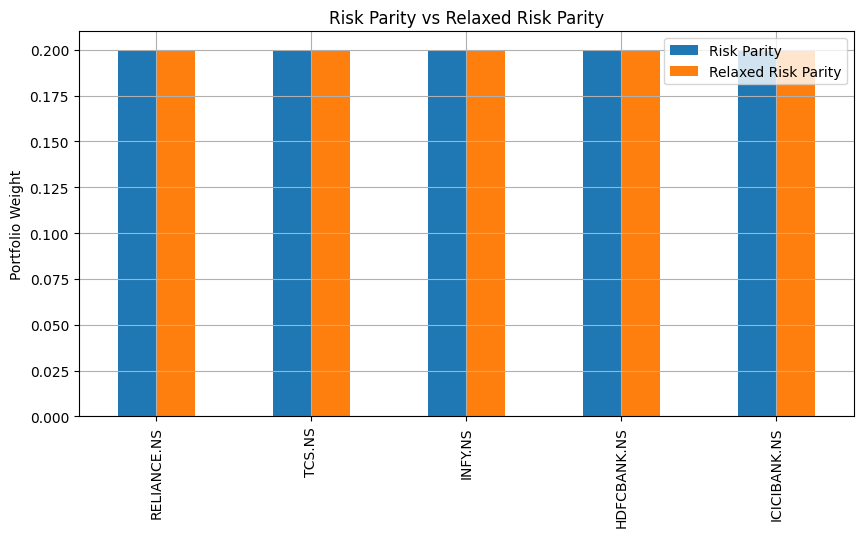

RP Weights: [0.2 0.2 0.2 0.2 0.2]
RRP Weights: [0.2 0.2 0.2 0.2 0.2]
Difference: [0. 0. 0. 0. 0.]


In [6]:
# --------------------------------------------
# Step 2: Covariance Matrix & Mean Returns
# --------------------------------------------

cov = returns.cov().values
mu = returns.mean().values

n = len(tickers)

# --------------------------------------------
# Step 3: Portfolio Volatility
# --------------------------------------------

def portfolio_volatility(weights, cov):
    return np.sqrt(weights.T @ cov @ weights)

# --------------------------------------------
# Step 4: Risk Contribution
# --------------------------------------------

def risk_contribution(weights, cov):
    sigma = portfolio_volatility(weights, cov)
    marginal = cov @ weights
    return weights * marginal / sigma

# --------------------------------------------
# Step 5: Risk Parity Objective
# --------------------------------------------

def risk_parity_objective(weights, cov):
    rc = risk_contribution(weights, cov)
    target = np.mean(rc)
    return np.sum((rc - target) ** 2)

# --------------------------------------------
# Step 6: Relaxed Risk Parity Objective
# --------------------------------------------

lam = 0.40

def relaxed_risk_parity(weights, cov, mu):
    rc = risk_contribution(weights, cov)
    target = np.mean(rc)

    risk_error = np.sum((rc - target) ** 2)
    expected_return = np.dot(mu, weights)

    return lam * risk_error - (1 - lam) * expected_return

# --------------------------------------------
# Step 7: Constraints
# --------------------------------------------

constraints = ({
    "type": "eq",
    "fun": lambda w: np.sum(w) - 1
})

bounds = [(0, 1)] * n
initial_weights = np.ones(n) / n

# --------------------------------------------
# Step 8: Risk Parity Optimization
# --------------------------------------------

rp_result = minimize(
    risk_parity_objective,
    initial_weights,
    args=(cov,),
    method="SLSQP",
    bounds=bounds,
    constraints=constraints
)

rp_weights = rp_result.x

# --------------------------------------------
# Step 9: Relaxed Risk Parity Optimization
# --------------------------------------------

rrp_result = minimize(
    relaxed_risk_parity,
    initial_weights,
    args=(cov, mu),
    method="SLSQP",
    bounds=bounds,
    constraints=constraints
)

rrp_weights = rrp_result.x

# --------------------------------------------
# Step 10: Portfolio Weights
# --------------------------------------------

comparison = pd.DataFrame({
    "Risk Parity": rp_weights,
    "Relaxed Risk Parity": rrp_weights
}, index=tickers)

print("\nPortfolio Weights")
print(comparison.round(4))

# --------------------------------------------
# Step 11: Risk Contributions
# --------------------------------------------

rp_rc = risk_contribution(rp_weights, cov)
rrp_rc = risk_contribution(rrp_weights, cov)

risk_table = pd.DataFrame({
    "RP Risk Contribution": rp_rc,
    "RRP Risk Contribution": rrp_rc
}, index=tickers)

print("\nRisk Contributions")
print(risk_table.round(6))

# --------------------------------------------
# Step 12: Portfolio Performance
# --------------------------------------------

def portfolio_stats(weights, returns):
    annual_return = np.dot(weights, returns.mean()) * 252
    annual_volatility = np.sqrt(weights.T @ (returns.cov().values * 252) @ weights)
    sharpe = annual_return / annual_volatility

    return annual_return, annual_volatility, sharpe

rp_ret, rp_vol, rp_sharpe = portfolio_stats(rp_weights, returns)
rrp_ret, rrp_vol, rrp_sharpe = portfolio_stats(rrp_weights, returns)

performance = pd.DataFrame({
    "Annual Return": [rp_ret, rrp_ret],
    "Annual Volatility": [rp_vol, rrp_vol],
    "Sharpe Ratio": [rp_sharpe, rrp_sharpe]
}, index=["Risk Parity", "Relaxed Risk Parity"])

print("\nPerformance")
print(performance.round(4))

# --------------------------------------------
# Step 13: Plot Portfolio Weights
# --------------------------------------------

comparison.plot(kind="bar", figsize=(10, 5))
plt.title("Risk Parity vs Relaxed Risk Parity")
plt.ylabel("Portfolio Weight")
plt.grid(True)
plt.show()

print("RP Weights:", rp_weights)
print("RRP Weights:", rrp_weights)
print("Difference:", rrp_weights - rp_weights)